# Human activity states with a Hidden Markov Model

This notebook follows the project rubric: inspect labeled Sensor Logger exports, extract time and FFT features, normalize using training data only, fit a Gaussian HMM with Baum–Welch, decode with Viterbi, and evaluate on recordings held out by recording session.

Each recording is one continuous activity. The held-out set uses recording suffixes 40–49 for each activity; those files are never used to estimate the feature scaler or HMM.


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.activity_hmm import (ACTIVITIES, FEATURE_NAMES, WINDOW_SECONDS, HOP_SECONDS,
    load_dataset, read_sensor, extract_recording, zscore, DiagonalGaussianHMM, evaluate)
DATA = ROOT / "data"
RESULTS = ROOT / "results"


## 1. Recording inventory and sampling

In [2]:
records = load_dataset(DATA)
for activity in ACTIVITIES:
    group = [r for r in records if r["activity"] == activity]
    print(f"{activity:9s}: {len(group):2d} recordings; {sum(len(r['X']) for r in group)} feature windows; "
          f"{sum(r['duration'] for r in group)/60:.2f} minutes; "
          f"observed median rate {np.median([r['fs'] for r in group]):.2f} Hz")
print("Total recordings:", len(records))
print("Nominal metadata request: 10 ms (100 Hz). We use measured timestamps; median actual rate:",
      f"{np.median([r['fs'] for r in records]):.2f} Hz")
print(f"Feature windows: {WINDOW_SECONDS:.1f} s, hop {HOP_SECONDS:.1f} s")


standing : 50 recordings; 345 feature windows; 6.91 minutes; observed median rate 57.35 Hz
walking  : 50 recordings; 354 feature windows; 7.20 minutes; observed median rate 57.34 Hz
jumping  : 50 recordings; 318 feature windows; 6.52 minutes; observed median rate 57.35 Hz
still    : 50 recordings; 345 feature windows; 7.00 minutes; observed median rate 57.35 Hz
Total recordings: 200
Nominal metadata request: 10 ms (100 Hz). We use measured timestamps; median actual rate: 57.35 Hz
Feature windows: 2.0 s, hop 1.0 s


All 200 recordings come from one Android handset. The app metadata requested a 10 ms period, but elapsed timestamps show an actual median rate around 57.35 Hz. Window placement uses each recording’s timestamps. FFT input is interpolated onto a uniform grid at the observed per-recording rate.


## 2. Inspect raw sensor data

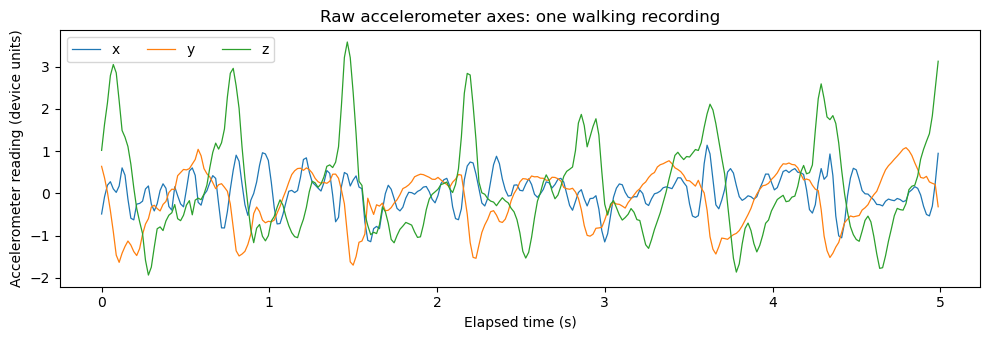

In [3]:
sample = next(r for r in records if r["activity"] == "walking")
t, acc = read_sensor(sample["folder"] / "Accelerometer.csv")
keep = (t - t[0]) <= 5
plt.figure(figsize=(10, 3.5))
for i, axis in enumerate(("x", "y", "z")):
    plt.plot(t[keep] - t[0], acc[keep, i], label=axis, linewidth=0.9)
plt.xlabel("Elapsed time (s)"); plt.ylabel("Accelerometer reading (device units)")
plt.title("Raw accelerometer axes: one walking recording"); plt.legend(ncol=3); plt.tight_layout()


## 3. Feature extraction

In [4]:
X_example, centers, fs, duration = extract_recording(sample["folder"])
print("Observed sample rate:", round(fs, 2), "Hz; recording duration:", round(duration, 2), "s")
print("Feature columns:", FEATURE_NAMES)
print("First feature windows:\n", np.round(X_example[:4], 4))


Observed sample rate: 57.35 Hz; recording duration: 8.13 s
Feature columns: ['acc_mag_mean', 'acc_mag_std', 'acc_sma', 'gyro_mag_rms', 'gyro_mag_std', 'acc_dominant_hz', 'acc_spectral_energy']
First feature windows:
 [[ 1.3028  0.7517  1.8868  0.5337  0.2777  1.4961 10.8031]
 [ 1.0829  0.7049  1.5689  0.5241  0.2969  2.9922 10.5237]
 [ 1.0901  0.6022  1.5824  0.4567  0.2599  2.4935  4.8498]
 [ 1.2107  0.5776  1.7598  0.4029  0.2109  1.4961  7.0963]]


Each two-second window contains about 115 observations at the measured rate; a one-second hop gives overlap and enough windows for temporal decoding. Features are acceleration magnitude mean and standard deviation, mean signal magnitude across axes (SMA), gyroscope magnitude RMS and standard deviation, dominant acceleration frequency in 0.5–12 Hz, and FFT band energy. Magnitude statistics summarize motion intensity while reducing orientation sensitivity; the frequency features capture repeated steps and jumps.

Z-score parameters are learned from training windows only and then applied to held-out windows. This puts features with different scales on comparable ranges without leaking test information.


## 4. Fit the HMM and evaluate unseen recordings

In [5]:
train = [r for r in records if r["index"] <= 39]
test = [r for r in records if r["index"] >= 40]
X_train, X_test, scaler_mean, scaler_sd = zscore([r["X"] for r in train], [r["X"] for r in test])
state_id = {a: i for i, a in enumerate(ACTIVITIES)}
model = DiagonalGaussianHMM(max_iter=100, tol=1e-4).fit(
    X_train, [state_id[r["activity"]] for r in train])
print(f"Baum-Welch iterations: {len(model.history)}; final train log-likelihood: {model.history[-1]:.2f}")
print("Training recordings:", len(train), "Unseen test recordings:", len(test))
# Evaluate() repeats this fit deterministically and saves all report artifacts.
model, cm, class_metrics, global_accuracy, n_train, n_test = evaluate(records, RESULTS)
print(f"Test windows: {cm.sum()}; global accuracy: {global_accuracy:.3%}")
for row in class_metrics: print(row)


Baum-Welch iterations: 6; final train log-likelihood: 7090.76
Training recordings: 160 Unseen test recordings: 40
Test windows: 267; global accuracy: 100.000%
{'activity': 'standing', 'n_test_windows': 68, 'sensitivity': np.float64(1.0), 'specificity': np.float64(1.0), 'accuracy_ovr': np.float64(1.0), 'precision': np.float64(1.0)}
{'activity': 'walking', 'n_test_windows': 69, 'sensitivity': np.float64(1.0), 'specificity': np.float64(1.0), 'accuracy_ovr': np.float64(1.0), 'precision': np.float64(1.0)}
{'activity': 'jumping', 'n_test_windows': 61, 'sensitivity': np.float64(1.0), 'specificity': np.float64(1.0), 'accuracy_ovr': np.float64(1.0), 'precision': np.float64(1.0)}
{'activity': 'still', 'n_test_windows': 69, 'sensitivity': np.float64(1.0), 'specificity': np.float64(1.0), 'accuracy_ovr': np.float64(1.0), 'precision': np.float64(1.0)}


Baum–Welch estimates initial-state, transition, and diagonal Gaussian emission parameters from training sequences, initialized from labeled training classes. It stops when relative log-likelihood improvement is at most 1e-4 (or 100 iterations). Viterbi finds the most likely hidden state sequence for each unseen recording. Sensitivity, specificity, one-vs-rest accuracy, and the confusion matrix compare decoded states with the known activity labels.


## 5. Transition, emission, decoded sequence, and confusion plots

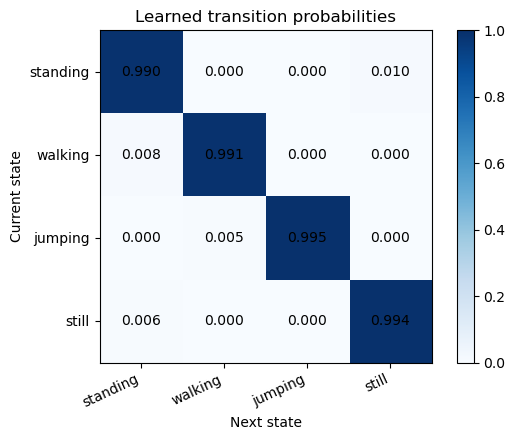

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(model.A, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4), ACTIVITIES, rotation=25, ha="right")
ax.set_yticks(range(4), ACTIVITIES); ax.set_xlabel("Next state"); ax.set_ylabel("Current state")
ax.set_title("Learned transition probabilities")
for i in range(4):
    for j in range(4): ax.text(j, i, f"{model.A[i,j]:.3f}", ha="center", va="center", color="black")
fig.colorbar(im, ax=ax); fig.tight_layout()


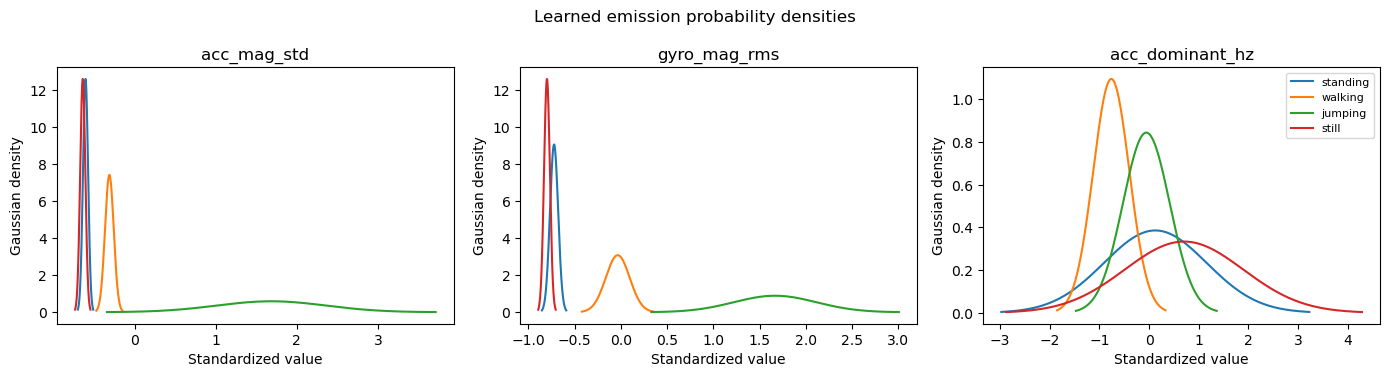

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, fi in zip(axes, [1, 3, 5]):
    for st, label in enumerate(ACTIVITIES):
        mu, var = model.means[st, fi], model.vars[st, fi]
        xs = np.linspace(mu - 3*np.sqrt(var), mu + 3*np.sqrt(var), 180)
        pdf = np.exp(-0.5*(xs-mu)**2/var) / np.sqrt(2*np.pi*var)
        ax.plot(xs, pdf, label=label)
    ax.set_title(FEATURE_NAMES[fi]); ax.set_xlabel("Standardized value"); ax.set_ylabel("Gaussian density")
axes[-1].legend(fontsize=8); fig.suptitle("Learned emission probability densities"); fig.tight_layout()


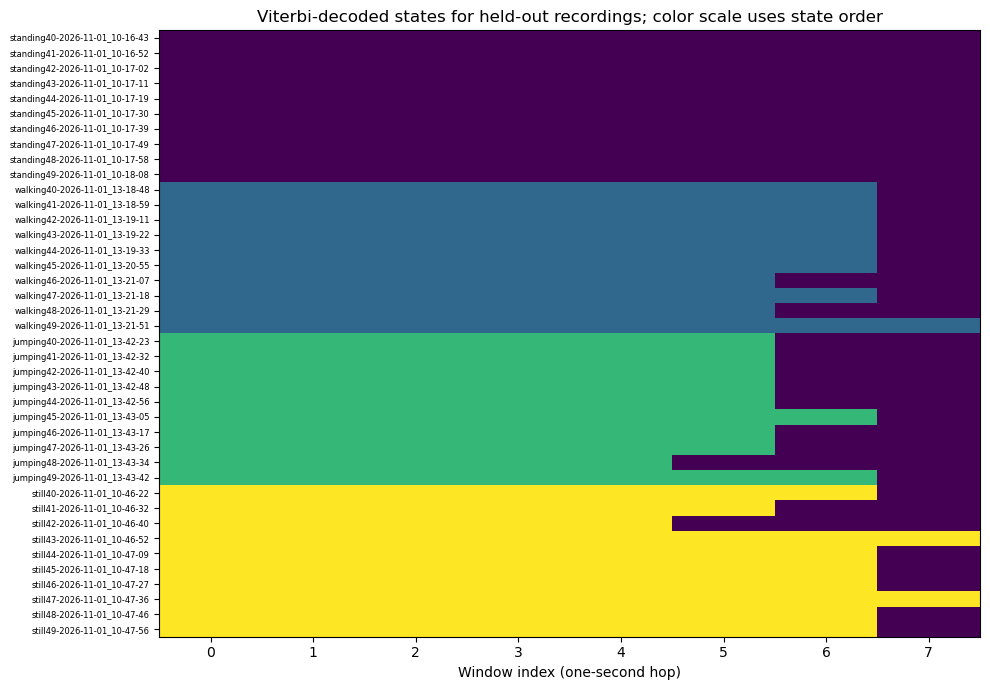

In [8]:
pred_sequences = []
for r, X in zip(test, X_test):
    pred_sequences.append(model.viterbi(X))
fig, ax = plt.subplots(figsize=(10, 7))
seq = np.array([np.pad(p, (0, max(map(len, pred_sequences))-len(p)), constant_values=-1) for p in pred_sequences])
im = ax.imshow(seq, aspect="auto", interpolation="nearest", vmin=0, vmax=3, cmap="viridis")
ax.set_yticks(range(len(test)), [r["recording"] for r in test], fontsize=6)
ax.set_xticks(range(0, seq.shape[1], 1)); ax.set_xlabel("Window index (one-second hop)")
ax.set_title("Viterbi-decoded states for held-out recordings; color scale uses state order")
fig.tight_layout()


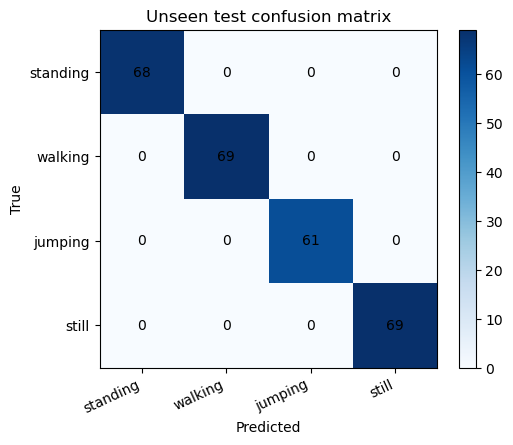

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im=ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4), ACTIVITIES, rotation=25, ha="right"); ax.set_yticks(range(4), ACTIVITIES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Unseen test confusion matrix")
for i in range(4):
    for j in range(4): ax.text(j, i, str(cm[i,j]), ha="center", va="center")
fig.colorbar(im, ax=ax); fig.tight_layout()


## Interpretation

The recordings are separate single-activity clips, so the learned transition matrix mainly describes persistence within a clip. It should not be read as a realistic daily activity-transition model. Overlapping windows are also correlated, and testing here is limited to one participant, device, and collection setup. A stronger generalization study would reserve a new participant/device session and include continuous recordings that move naturally between activities.
